# CSCI1409 Deep Learning, Week 7 SIS Mini-project 2
## CIFAR-10: your own CNN, Dropout, and why accuracy is not enough

SIS mini-project 2: 4 course points · Defense: in class, Week 7

This lab covers both Week 7 topics: regularization (Dropout) and model evaluation metrics.

Goal: design and code your own CNN for color images, train it twice (without and with Dropout), and check how good it really is with more than accuracy: precision, recall, F1, average precision (AP) and a confusion matrix. At the end you tune the decision threshold for the two rare classes.

One twist: in this lab cats and dogs are rare. Imagine an app where most photos show planes, cars, ships, birds or horses, and only a few show cats or dogs. You will find out how well your models work on these rare classes, and how much a better threshold can help.

The most important rule of this lab: every decision (which model is best, which threshold to use) is made on the validation set. The test set is used once, in section 8, after all decisions are made.

You work in groups of 3. Apart from the dataset download, all code in this notebook is written by your group. No ready-made or pretrained networks: you build the CNN yourselves from PyTorch layers. The cells only contain `# TODO` comments with hints. Every student must be able to explain every line and every plot. Write short answers in the answer cells (2 to 4 sentences each is enough), and every answer must use your own numbers.

Before class: make sure `torch`, `torchvision`, `matplotlib` and `scikit-learn` are installed ([PyTorch setup guide](https://pytorch.org/get-started/locally/)). The first download of CIFAR-10 (about 170 MB) needs internet. A CPU is enough, no GPU needed. Training both models for 15 epochs takes roughly 10 to 30 minutes on a laptop CPU, depending on the size of your CNN, so do not start the night before. A GPU (for example free Google Colab) makes it faster but is not required.

### Как запускать решение

Все решения и пояснения добавлены ниже; ответы с числами вычисляются из результатов текущего запуска. Запустите **Run All** в Jupyter или Google Colab. Нужны `torch`, `torchvision`, `numpy`, `matplotlib`, `scikit-learn`; при необходимости установите их через `%pip install torch torchvision numpy matplotlib scikit-learn` в отдельной ячейке.

Данные скачиваются в `./data`. Исходный архив берётся с [зеркала CIFAR-10](https://huggingface.co/datasets/liangnanying/cifar-10-python/tree/main); torchvision проверяет официальный MD5 `c58f30108f718f92721af3b95e74349a`. Используется простая CNN из трёх свёрток и двух Linear, Adam, lr=0.001, batch=64, 15 эпох. По умолчанию работает CUDA, если доступна, иначе CPU. Для честного сравнения совпадают начальные веса и порядок batch; абсолютное совпадение чисел между разными устройствами и версиями библиотек не гарантируется.

Решены также необязательные пункты: weighted B обучается отдельно до тестовой части; ROC, cat override и план проверки «редкость или сложность» находятся в конце. Это ещё 15 эпох обучения. ФИО участников указаны; дополните таблицу их реальным вкладом.


## 1. Dataset

CIFAR-10 has 32×32 color images in 10 classes: airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck. The download code is given.

You build three sets with the sizes below. Cats (class 3) and dogs (class 5) get 10 times fewer images than the other classes, in all three sets.

| Set | Taken from | Each of the 8 other classes | Cat | Dog | Total |
|---|---|---|---|---|---|
| Train | official training portion | 1,000 | 100 | 100 | 8,200 |
| Validation | official training portion, images not used in train | 500 | 50 | 50 | 4,100 |
| Test | official test set | 1,000 | 100 | 100 | 8,200 |

The validation set is bigger than you may expect. In section 7 you use it to choose thresholds for cats and dogs, and with only a few cats that choice would be very noisy.

Key words:
- Training set: the images the model learns from.
- Validation set: images used to check the model during training and to make decisions (best model, thresholds).
- Test set: images used only once, at the very end, after all decisions are made. In this lab that is section 8.

In [1]:
from torchvision import datasets, transforms

DATA_ROOT = "./data"

# Тот же исходный архив с быстрого зеркала; torchvision проверяет официальный MD5.
datasets.CIFAR10.url = "https://huggingface.co/datasets/liangnanying/cifar-10-python/resolve/main/cifar-10-python.tar.gz"

full_train = datasets.CIFAR10(root=DATA_ROOT, train=True, download=True, transform=transforms.ToTensor())
full_test = datasets.CIFAR10(root=DATA_ROOT, train=False, download=True, transform=transforms.ToTensor())

print("Official training portion:", len(full_train), "images")
print("Official test set:", len(full_test), "images")
print("Classes:", full_train.classes)

100.0%


Official training portion: 50000 images
Official test set: 10000 images
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [2]:
import random
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
import matplotlib.pyplot as plt
from sklearn import metrics
from IPython.display import display, Markdown

SEED = 42

def set_seed():
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

set_seed()
torch.set_num_threads(4)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("PyTorch:", torch.__version__)
plt.rcParams["figure.dpi"] = 110

Device: cpu
PyTorch: 2.13.0


In [3]:
train_indices, val_indices, test_indices = [], [], []
train_labels = torch.tensor(full_train.targets)
test_labels = torch.tensor(full_test.targets)
classes = full_train.classes
rare_classes = [3, 5]

for c in range(10):
    indices = torch.where(train_labels == c)[0]
    indices = indices[torch.randperm(len(indices))]
    n_train = 100 if c in rare_classes else 1000
    n_val = 50 if c in rare_classes else 500
    train_indices.extend(indices[:n_train].tolist())
    val_indices.extend(indices[n_train:n_train + n_val].tolist())

    indices = torch.where(test_labels == c)[0]
    indices = indices[torch.randperm(len(indices))]
    n_test = 100 if c in rare_classes else 1000
    test_indices.extend(indices[:n_test].tolist())

train_set = Subset(full_train, train_indices)
val_set = Subset(full_train, val_indices)
test_set = Subset(full_test, test_indices)
assert set(train_indices).isdisjoint(val_indices)
assert (len(train_set), len(val_set), len(test_set)) == (8200, 4100, 8200)
print("Train:", len(train_set), "Validation:", len(val_set), "Test:", len(test_set))

Train: 8200 Validation: 4100 Test: 8200


Class         Train    Val   Test
airplane       1000    500   1000
automobile     1000    500   1000
bird           1000    500   1000
cat             100     50    100
deer           1000    500   1000
dog             100     50    100
frog           1000    500   1000
horse          1000    500   1000
ship           1000    500   1000
truck          1000    500   1000


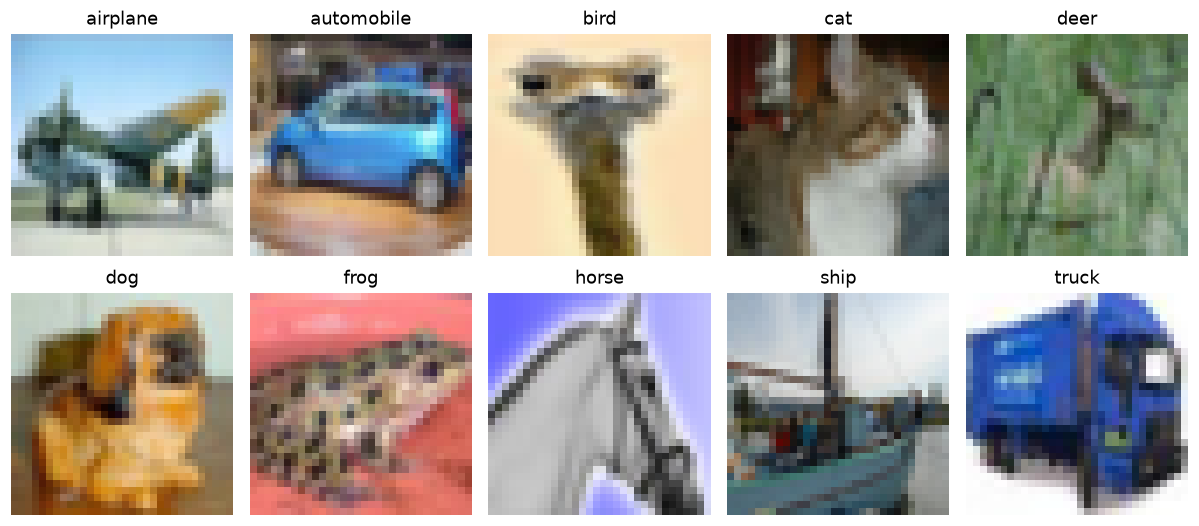

In [4]:
train_counts = np.bincount(train_labels[train_indices].numpy(), minlength=10)
val_counts = np.bincount(train_labels[val_indices].numpy(), minlength=10)
test_counts = np.bincount(test_labels[test_indices].numpy(), minlength=10)
print(f"{'Class':12} {'Train':>6} {'Val':>6} {'Test':>6}")
for c, name in enumerate(classes):
    print(f"{name:12} {train_counts[c]:6} {val_counts[c]:6} {test_counts[c]:6}")
    assert train_counts[c] == (100 if c in rare_classes else 1000)
    assert val_counts[c] == (50 if c in rare_classes else 500)
    assert test_counts[c] == (100 if c in rare_classes else 1000)

fig, axes = plt.subplots(2, 5, figsize=(11, 5))
for c, ax in enumerate(axes.flat):
    index = next(i for i in train_indices if full_train.targets[i] == c)
    image, label = full_train[index]
    ax.imshow(image.permute(1, 2, 0))
    ax.set_title(classes[label])
    ax.axis("off")
plt.tight_layout()
plt.show()

#### Your answers: dataset

- What does the shape `[3, 32, 32]` mean? How is it different from FashionMNIST?
- What share of the test set are cats and dogs together?
- Why do we use the test set only once, at the end?

Ответы с результатами текущего запуска — в следующей ячейке.

In [5]:
display(Markdown(f"""
1. `[3, 32, 32]` — это 3 цветовых канала RGB, высота 32 и ширина 32 пикселя. У FashionMNIST один канал и размер 28×28: `[1, 28, 28]`.
2. Кошек и собак вместе **{test_counts[3] + test_counts[5]} / {len(test_set)} = {100 * (test_counts[3] + test_counts[5]) / len(test_set):.2f}%** тестовых изображений.
3. Test нужен для окончательной проверки на данных, которые не влияли на решения. Если выбирать по нему модель или пороги, результат станет слишком оптимистичным; здесь все решения принимаются по validation.
"""))


1. `[3, 32, 32]` — это 3 цветовых канала RGB, высота 32 и ширина 32 пикселя. У FashionMNIST один канал и размер 28×28: `[1, 28, 28]`.
2. Кошек и собак вместе **200 / 8200 = 2.44%** тестовых изображений.
3. Test нужен для окончательной проверки на данных, которые не влияли на решения. Если выбирать по нему модель или пороги, результат станет слишком оптимистичным; здесь все решения принимаются по validation.


## 2. Design your CNN

You design one CNN architecture and train it twice:
- Model A: your CNN without Dropout.
- Model B: exactly the same CNN with Dropout added. Nothing else changes.

Rules for your CNN:

| Rule | Requirement |
|---|---|
| Written by you | Build it from PyTorch layers: `nn.Conv2d`, `nn.ReLU`, `nn.MaxPool2d`, `nn.Flatten`, `nn.Linear`, `nn.Dropout`. Not allowed: `torchvision.models`, `timm`, pretrained weights, or a network copied from a tutorial. |
| Depth | 5 to 10 layers with weights. Count `Conv2d` and `Linear` layers together. ReLU, MaxPool, Flatten and Dropout have no weights, so they do not count. |
| Convolution | At least 3 `Conv2d` layers, each followed by `ReLU`. |
| Pooling | At least 2 `MaxPool2d` layers. |
| Classifier head | `Flatten`, then at least one hidden `Linear` layer with `ReLU`, then `Linear(…, 10)`. |
| Output | 10 logits. No softmax inside the model: `nn.CrossEntropyLoss` applies it for you. |

`nn.BatchNorm2d` is allowed if you can explain what it does, but it is not required.

An example that follows the rules (6 layers with weights). You may use it or design your own:

- Block 1: `Conv2d(3, 32, kernel_size=3, padding=1) → ReLU → Conv2d(32, 32, kernel_size=3, padding=1) → ReLU → MaxPool2d(2)`
- Block 2: `Conv2d(32, 64, kernel_size=3, padding=1) → ReLU → Conv2d(64, 64, kernel_size=3, padding=1) → ReLU → MaxPool2d(2)`
- Head: `Flatten → Linear(?, 256) → ReLU → Linear(256, 10)`

Finding the number in place of `?` for your own CNN is part of the task.

Dropout for Model B:
- Required: `nn.Dropout(p=0.5)` right after the hidden `ReLU`, before the output `Linear`.
- Recommended: also `nn.Dropout(p=0.25)` right after `Flatten`.
- You may try other places or values of `p`, but choose using the validation set and write down what you tried.

In [6]:
def make_cnn(use_dropout):
    layers = [
        nn.Conv2d(3, 16, 3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Conv2d(16, 32, 3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Conv2d(32, 64, 3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Flatten(),
    ]
    if use_dropout:
        layers.append(nn.Dropout(0.25))
    layers.extend([nn.Linear(64 * 4 * 4, 128), nn.ReLU()])
    if use_dropout:
        layers.append(nn.Dropout(0.5))
    layers.append(nn.Linear(128, 10))
    return nn.Sequential(*layers)

In [7]:
parameter_counts = {}
shape_rows = []
for name, use_dropout in [("A", False), ("B", True)]:
    model = make_cnn(use_dropout)
    x = torch.zeros(4, 3, 32, 32)
    print(f"\nModel {name}")
    for layer in model:
        x = layer(x)
        print(f"{str(layer):65} -> {tuple(x.shape)}")
        if name == "A":
            shape_rows.append(f"| `{layer}` | `{list(x.shape)}` |")
    assert x.shape == (4, 10)
    conv_layers = [layer for layer in model if isinstance(layer, nn.Conv2d)]
    linear_layers = [layer for layer in model if isinstance(layer, nn.Linear)]
    assert 5 <= len(conv_layers) + len(linear_layers) <= 10
    assert len(conv_layers) >= 3
    assert sum(isinstance(layer, nn.MaxPool2d) for layer in model) >= 2
    for i, layer in enumerate(model):
        if isinstance(layer, nn.Conv2d):
            assert isinstance(model[i + 1], nn.ReLU)
    flat_index = next(i for i, layer in enumerate(model) if isinstance(layer, nn.Flatten))
    hidden_index = next(i for i, layer in enumerate(model) if isinstance(layer, nn.Linear))
    assert flat_index < hidden_index
    assert len(linear_layers) >= 2 and isinstance(model[hidden_index + 1], nn.ReLU)
    assert isinstance(model[-1], nn.Linear) and model[-1].out_features == 10
    assert not any(isinstance(layer, nn.Softmax) for layer in model)
    if use_dropout:
        assert isinstance(model[-2], nn.Dropout) and model[-2].p == 0.5
        assert isinstance(model[-3], nn.ReLU)
    total = sum(p.numel() for p in model.parameters() if p.requires_grad)
    conv = sum(p.numel() for layer in conv_layers for p in layer.parameters())
    linear = sum(p.numel() for layer in linear_layers for p in layer.parameters())
    parameter_counts[name] = (total, conv, linear)
    print("Weighted layers:", len(conv_layers) + len(linear_layers))
    print("Parameters: total =", total, "; conv =", conv, "; linear =", linear)
assert parameter_counts["A"] == parameter_counts["B"]
assert parameter_counts["A"][0] == sum(parameter_counts["A"][1:])
assert sum(p.numel() for p in make_cnn(False)[0].parameters()) == (3 * 3 * 3 + 1) * 16


Model A
Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))  -> (4, 16, 32, 32)
ReLU()                                                            -> (4, 16, 32, 32)
MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False) -> (4, 16, 16, 16)
Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1)) -> (4, 32, 16, 16)
ReLU()                                                            -> (4, 32, 16, 16)
MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False) -> (4, 32, 8, 8)
Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1)) -> (4, 64, 8, 8)
ReLU()                                                            -> (4, 64, 8, 8)
MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False) -> (4, 64, 4, 4)
Flatten(start_dim=1, end_dim=-1)                                  -> (4, 1024)
Linear(in_features=1024, out_features=128, bias=True)             -> (4, 128)
ReLU()                                            

#### Your answers: your CNN

- Write your architecture as a list of layers with the output shape after each one. How many layers with weights does it have?
- What number did you put in place of `?`, and how did you get it? Show how height and width change after every `Conv2d` and `MaxPool2d`.
- How many parameters does your CNN have in total, in the conv layers, and in the linear layers? Compute the parameters of one `Conv2d` layer by hand and check it against your code.
- Why do the conv layers need so few parameters? Think about what a 3×3 filter looks at, and that the same filter slides over the whole image.
- Why do Model A and Model B have exactly the same number of parameters? Why is there no softmax at the end of your model?

Ответы с результатами текущего запуска — в следующей ячейке.

In [8]:
display(Markdown("| Слой модели A | Размер выхода, batch=4 |\n|---|---|\n" + "\n".join(shape_rows)))
total, conv, linear = parameter_counts["A"]
display(Markdown(f"""
- **5 слоёв с весами:** 3 Conv2d и 2 Linear. У B после Flatten добавлен Dropout(0.25), а после скрытого ReLU — Dropout(0.5); размеры тензоров не меняются.
- У свёрток `kernel_size=3, padding=1, stride=1`, поэтому высота и ширина сохраняются: 32→32, 16→16, 8→8. Три MaxPool2d(2) уменьшают стороны: 32→16→8→4. Поэтому первый Linear получает **64×4×4 = 1024** числа.
- Всего **{total:,}** параметров: **{conv:,}** в свёртках и **{linear:,}** в Linear. В первой свёртке 16 фильтров по 3×3×3 веса плюс одно смещение на фильтр: **(3×3×3 + 1)×16 = 448**; это совпало с кодом.
- Свёртка смотрит на маленькую область 3×3 и применяет одни и те же веса во всех позициях. Поэтому число её параметров не зависит от высоты и ширины изображения.
- У Dropout нет обучаемых параметров, так что A и B имеют одинаковое их число. В конце нужны logits: `CrossEntropyLoss` уже включает нужное преобразование; softmax используем отдельно только для вероятностей и метрик.
"""))

| Слой модели A | Размер выхода, batch=4 |
|---|---|
| `Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))` | `[4, 16, 32, 32]` |
| `ReLU()` | `[4, 16, 32, 32]` |
| `MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)` | `[4, 16, 16, 16]` |
| `Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))` | `[4, 32, 16, 16]` |
| `ReLU()` | `[4, 32, 16, 16]` |
| `MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)` | `[4, 32, 8, 8]` |
| `Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))` | `[4, 64, 8, 8]` |
| `ReLU()` | `[4, 64, 8, 8]` |
| `MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)` | `[4, 64, 4, 4]` |
| `Flatten(start_dim=1, end_dim=-1)` | `[4, 1024]` |
| `Linear(in_features=1024, out_features=128, bias=True)` | `[4, 128]` |
| `ReLU()` | `[4, 128]` |
| `Linear(in_features=128, out_features=10, bias=True)` | `[4, 10]` |


- **5 слоёв с весами:** 3 Conv2d и 2 Linear. У B после Flatten добавлен Dropout(0.25), а после скрытого ReLU — Dropout(0.5); размеры тензоров не меняются.
- У свёрток `kernel_size=3, padding=1, stride=1`, поэтому высота и ширина сохраняются: 32→32, 16→16, 8→8. Три MaxPool2d(2) уменьшают стороны: 32→16→8→4. Поэтому первый Linear получает **64×4×4 = 1024** числа.
- Всего **156,074** параметров: **23,584** в свёртках и **132,490** в Linear. В первой свёртке 16 фильтров по 3×3×3 веса плюс одно смещение на фильтр: **(3×3×3 + 1)×16 = 448**; это совпало с кодом.
- Свёртка смотрит на маленькую область 3×3 и применяет одни и те же веса во всех позициях. Поэтому число её параметров не зависит от высоты и ширины изображения.
- У Dropout нет обучаемых параметров, так что A и B имеют одинаковое их число. В конце нужны logits: `CrossEntropyLoss` уже включает нужное преобразование; softmax используем отдельно только для вероятностей и метрик.


## 3. Training setup

Use these settings for both models (you may change them, but write down what you used):

| Setting | Value |
|---|---|
| Optimizer | Adam |
| Learning rate | 0.001 |
| Batch size | 64 |
| Epochs | 15 |

Keep the seed, optimizer, learning rate, batch size and number of epochs the same for both models. Only Dropout changes, so the comparison is fair. We use 15 epochs so that overfitting has time to show up.

In [9]:
BATCH_SIZE = 64
LEARNING_RATE = 0.001
EPOCHS = 15

# Отдельный генератор: Dropout не меняет порядок тренировочных batch.
train_generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True,
                          generator=train_generator, num_workers=0)
train_eval_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=False)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False)
loss_fn = nn.CrossEntropyLoss()
print("Adam; lr =", LEARNING_RATE, "; batch =", BATCH_SIZE, "; epochs =", EPOCHS)

Adam; lr = 0.001 ; batch = 64 ; epochs = 15


#### Прогноз до обучения

Ожидаю, что у B validation accuracy будет выше: Dropout должен уменьшить зависимость от отдельных нейронов и улучшить обобщение. У A train loss, скорее всего, будет меньше, но validation loss раньше перестанет снижаться; у B ожидаю меньший разрыв между этими кривыми.

Хуже всего ожидаю распознавание кошек и собак: их всего по 100 в train против 1000 у других классов, и маленькие изображения животных похожи друг на друга. Это гипотеза до обучения, а не вывод из test.


## 4. Training and evaluation code

You can reuse `train_one_epoch` and `evaluate` from SIS 1. Changes: move every batch to your device (`images.to(device)`, `labels.to(device)`), move each model to the device after you build it, and switch between train and eval mode correctly, because Dropout depends on it.

Key words:
- Overfitting: the training loss keeps going down, but the validation loss stops improving or goes up. The model memorises the training images instead of learning patterns that also work on new images.
- Regularization: any method that reduces overfitting. Dropout is one of them.
- Dropout with probability `p`: during training, every value that enters the Dropout layer is set to zero with probability `p`, independently for every image and every step. The network cannot rely on one single neuron, so it learns features that still work when some neurons are missing (Goodfellow et al., *Deep Learning*, Section 7.12).
- Inverted dropout: during training, PyTorch multiplies the values that are kept by `1 / (1 − p)`. Because of this, the average value is the same in training and in evaluation, and nothing needs to be rescaled at test time.
- `model.train()` and `model.eval()`: Dropout is active only in train mode. In eval mode it passes values through unchanged. So `train_one_epoch` must call `model.train()` and `evaluate` must call `model.eval()`. Forgetting this is one of the most common bugs with Dropout.

In [10]:
def train_one_epoch(model, loader, loss_fn, optimizer):
    model.train()
    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)
        optimizer.zero_grad()
        logits = model(images)
        loss = loss_fn(logits, labels)
        loss.backward()
        optimizer.step()

In [11]:
def evaluate(model, loader, loss_fn):
    model.eval()
    total_loss, correct, count = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)
            logits = model(images)
            loss = loss_fn(logits, labels)
            total_loss += loss.item() * len(labels)
            correct += (logits.argmax(1) == labels).sum().item()
            count += len(labels)
    return total_loss / count, correct / count

In [12]:
def run_experiment(model):
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    train_losses, val_losses, val_accuracies = [], [], []
    for epoch in range(EPOCHS):
        train_one_epoch(model, train_loader, loss_fn, optimizer)
        train_loss, _ = evaluate(model, train_eval_loader, loss_fn)
        val_loss, val_acc = evaluate(model, val_loader, loss_fn)
        train_losses.append(train_loss)
        val_losses.append(val_loss)
        val_accuracies.append(val_acc)
        print(f"Epoch {epoch + 1:2}/{EPOCHS}: train loss={train_loss:.4f}, "
              f"val loss={val_loss:.4f}, val accuracy={val_acc:.4f}", flush=True)
    return {"train_loss": train_losses, "val_loss": val_losses,
            "val_accuracy": val_accuracies}

## 5. Train both models

In [13]:
set_seed()
train_generator.manual_seed(SEED)
model_a = make_cnn(False).to(device)
initial_a = [p.detach().cpu().clone() for p in model_a.parameters()]
history_a = run_experiment(model_a)

Epoch  1/15: train loss=1.7812, val loss=1.7969, val accuracy=0.3285


Epoch  2/15: train loss=1.4761, val loss=1.5095, val accuracy=0.4405


Epoch  3/15: train loss=1.3631, val loss=1.3956, val accuracy=0.4920


Epoch  4/15: train loss=1.2851, val loss=1.3336, val accuracy=0.5156


Epoch  5/15: train loss=1.2091, val loss=1.2699, val accuracy=0.5502


Epoch  6/15: train loss=1.1553, val loss=1.2302, val accuracy=0.5644


... (5 outputs left out)

Epoch 12/15: train loss=0.9559, val loss=1.1556, val accuracy=0.6029


Epoch 13/15: train loss=0.8551, val loss=1.1056, val accuracy=0.6198


Epoch 14/15: train loss=0.8036, val loss=1.0700, val accuracy=0.6307


Epoch 15/15: train loss=0.7747, val loss=1.1090, val accuracy=0.6224


In [14]:
set_seed()
train_generator.manual_seed(SEED)
model_b = make_cnn(True).to(device)
assert all(torch.equal(a, b.detach().cpu()) for a, b in zip(initial_a, model_b.parameters()))
history_b = run_experiment(model_b)

Epoch  1/15: train loss=1.6916, val loss=1.7033, val accuracy=0.3690


Epoch  2/15: train loss=1.5215, val loss=1.5457, val accuracy=0.4249


Epoch  3/15: train loss=1.4131, val loss=1.4386, val accuracy=0.4673


Epoch  4/15: train loss=1.3709, val loss=1.4060, val accuracy=0.4841


Epoch  5/15: train loss=1.2806, val loss=1.3252, val accuracy=0.5193


Epoch  6/15: train loss=1.2642, val loss=1.3223, val accuracy=0.5117


... (5 outputs left out)

Epoch 12/15: train loss=1.0365, val loss=1.1569, val accuracy=0.5868


Epoch 13/15: train loss=0.9841, val loss=1.1221, val accuracy=0.6085


Epoch 14/15: train loss=0.9646, val loss=1.1051, val accuracy=0.6095


Epoch 15/15: train loss=0.9238, val loss=1.0902, val accuracy=0.6156


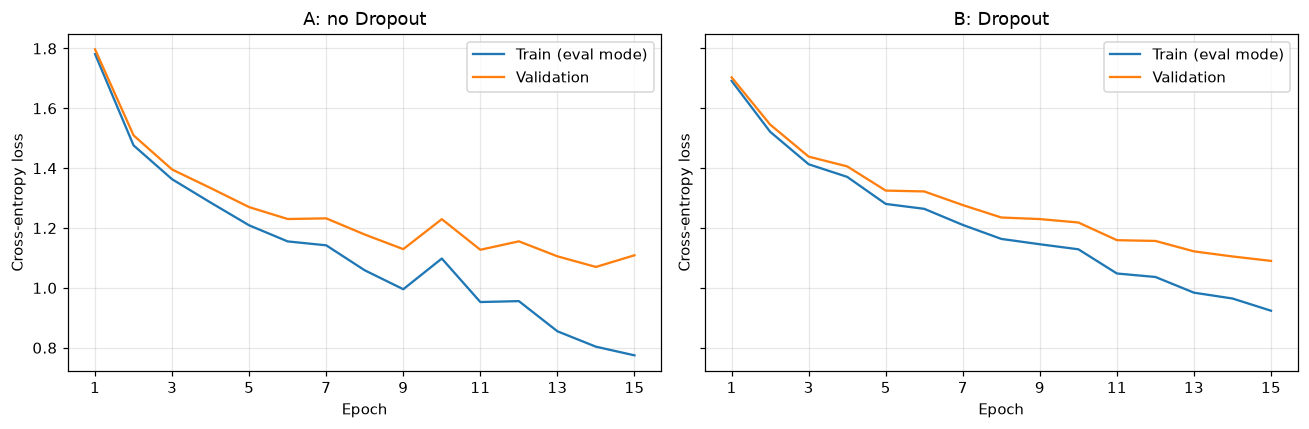

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
epochs = range(1, EPOCHS + 1)
for ax, name, history in zip(axes, ["A: no Dropout", "B: Dropout"], [history_a, history_b]):
    ax.plot(epochs, history["train_loss"], label="Train (eval mode)")
    ax.plot(epochs, history["val_loss"], label="Validation")
    ax.set(title=name, xlabel="Epoch", ylabel="Cross-entropy loss")
    ax.set_xticks(range(1, EPOCHS + 1, 2))
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [16]:
dropout_accuracies = [evaluate(model_b, val_loader, loss_fn)[1]]
for _ in range(2):
    model_b.train()
    correct, count = 0, 0
    with torch.no_grad():
        for images, labels in val_loader:
            logits = model_b(images.to(device))
            correct += (logits.argmax(1).cpu() == labels).sum().item()
            count += len(labels)
    dropout_accuracies.append(correct / count)
model_b.eval()
for mode, acc in zip(["eval", "train run 1", "train run 2"], dropout_accuracies):
    print(f"{mode:12}: accuracy = {acc:.4f}")

eval        : accuracy = 0.6156
train run 1 : accuracy = 0.5693
train run 2 : accuracy = 0.5863


#### Your answers: loss curves and Dropout

- Give the final train loss and validation loss of both models. Which model has the lower validation loss?
- Does Model A overfit? If yes, from which epoch? Compare the gap between train and validation loss at the last epoch for Model A and Model B. What did Dropout change?
- Write the three accuracies from the Dropout experiment. Why is the train-mode accuracy lower, and why do the two train-mode runs give different numbers?
- If you print the loss of each batch during training (Dropout on), Model B's training loss can be higher than its validation loss. Why is this not a bug?
- Was your prediction right?

Ответы с результатами текущего запуска — в следующей ячейке.

In [17]:
gap_a = history_a["val_loss"][-1] - history_a["train_loss"][-1]
gap_b = history_b["val_loss"][-1] - history_b["train_loss"][-1]
min_a = int(np.argmin(history_a["val_loss"]))
lower_loss = "A" if history_a["val_loss"][-1] < history_b["val_loss"][-1] else "B"
acc_winner = "A" if history_a["val_accuracy"][-1] > history_b["val_accuracy"][-1] else "B"
if min_a < EPOCHS - 1:
    overfit_text = (f"Минимум validation loss у A был на эпохе {min_a + 1}; "
                   f"после неё (с эпохи {min_a + 2}) видны признаки переобучения. "
                   "Отдельные колебания сами по себе ещё не доказывают переобучение.")
else:
    overfit_text = "До последней эпохи устойчивого роста validation loss у A не видно; одного разрыва недостаточно, чтобы назвать точную эпоху переобучения."
display(Markdown(f"""
1. Последняя эпоха: A — train loss **{history_a['train_loss'][-1]:.4f}**, val loss **{history_a['val_loss'][-1]:.4f}**; B — **{history_b['train_loss'][-1]:.4f}** и **{history_b['val_loss'][-1]:.4f}**. Меньше validation loss у **{lower_loss}**.
2. {overfit_text} Финальный разрыв val−train: A **{gap_a:.4f}**, B **{gap_b:.4f}**. Dropout {'уменьшил' if gap_b < gap_a else 'не уменьшил'} этот разрыв.
3. Accuracy B: eval **{dropout_accuracies[0]:.4f}**, train №1 **{dropout_accuracies[1]:.4f}**, train №2 **{dropout_accuracies[2]:.4f}**. В train случайно выключаются нейроны, поэтому отдельный проход обычно менее точен, а два прохода могут давать разные результаты. `no_grad()` отключает градиенты, но не Dropout.
4. Во время обучения B решает более сложную задачу со случайно выключенными нейронами; при validation они все работают. Поэтому loss batch с Dropout может быть выше validation loss — это нормально. Сохранённые на графике train и val loss оба измерены в eval mode.
5. Я ожидал преимущество B по validation accuracy и большее переобучение A. По accuracy в последнюю эпоху победила **{acc_winner}**, так что эта часть прогноза {'подтвердилась' if acc_winner == 'B' else 'не подтвердилась'}; вывод о переобучении основан на loss выше.
"""))


1. Последняя эпоха: A — train loss **0.7747**, val loss **1.1090**; B — **0.9238** и **1.0902**. Меньше validation loss у **B**.
2. Минимум validation loss у A был на эпохе 14; после неё (с эпохи 15) видны признаки переобучения. Отдельные колебания сами по себе ещё не доказывают переобучение. Финальный разрыв val−train: A **0.3343**, B **0.1664**. Dropout уменьшил этот разрыв.
3. Accuracy B: eval **0.6156**, train №1 **0.5693**, train №2 **0.5863**. В train случайно выключаются нейроны, поэтому отдельный проход обычно менее точен, а два прохода могут давать разные результаты. `no_grad()` отключает градиенты, но не Dropout.
4. Во время обучения B решает более сложную задачу со случайно выключенными нейронами; при validation они все работают. Поэтому loss batch с Dropout может быть выше validation loss — это нормально. Сохранённые на графике train и val loss оба измерены в eval mode.
5. Я ожидал преимущество B по validation accuracy и большее переобучение A. По accuracy в последнюю эпоху победила **A**, так что эта часть прогноза не подтвердилась; вывод о переобучении основан на loss выше.


## 6. Metrics on the validation set

Before you touch the test set, you compute all metrics on the validation set and use them to choose your best model. Write the metric functions once: in section 8 you use the same functions on the test set.

Key words, part 1 (one predicted class per image):
- Confusion matrix: a 10 × 10 table. Row = true class, column = predicted class. Cell `[i, j]` counts images of class `i` that the model predicted as class `j`.
- Precision of a class: of all images the model called "cat", how many really are cats. `precision = TP / (TP + FP)`
- Recall of a class: of all real cats, how many the model found. `recall = TP / (TP + FN)`
- F1 of a class: `2 · precision · recall / (precision + recall)`. It is high only when both are high.
- Macro F1: the plain average of the 10 per-class F1 scores. Every class counts the same.
- Weighted F1: the average of the per-class F1 scores, weighted by how many images each class has. Big classes count more.

Here TP (true positive) = real cat predicted as cat, FP (false positive) = not a cat but predicted as cat, FN (false negative) = real cat predicted as something else.

Key words, part 2 (scores and ranking):
- Score for class `c`: the softmax probability `p(c | image)`. A higher score means the model is more sure the image belongs to class `c`.
- Precision-recall (PR) curve: sort all images by their score for class `c`, highest first. Call the top `k` images "predicted c" and compute precision and recall. Every `k` gives one point (recall, precision).
- precision@k: the share of real class-`c` images among the top `k`.
- Average precision (AP) of class `c`: the average of precision@k over the ranks `k` where a real class-`c` image appears. `AP = (precision@k₁ + precision@k₂ + … + precision@k_P) / P`, where `P` is the number of real class-`c` images and `k₁, …, k_P` are their ranks. AP = 1.0 when all class-`c` images are ranked above all other images. AP uses no threshold: it measures how well the model ranks the images.
- Random baseline: a model that gives random scores gets AP of about the share of class `c` in the data. For a rare class this baseline is very small.
- Macro AP (also called mAP, mean average precision): the plain average of the 10 per-class APs.

Worked example for AP. Five images, sorted by their cat score:

| Rank k | 1 | 2 | 3 | 4 | 5 |
|---|---|---|---|---|---|
| Score for cat | 0.9 | 0.8 | 0.7 | 0.6 | 0.5 |
| Real cat? | yes | no | yes | no | no |
| precision@k | 1/1 | 1/2 | 2/3 | 2/4 | 2/5 |

The real cats are at ranks 1 and 3, so `AP = (1/1 + 2/3) / 2 = 0.833`. Your AP function must give 0.833 on this example.

In [18]:
def get_predictions(model, loader):
    model.eval()
    true_labels, probabilities = [], []
    with torch.no_grad():
        for images, labels in loader:
            logits = model(images.to(device))
            true_labels.append(labels.cpu())
            probabilities.append(torch.softmax(logits, dim=1).cpu())
    true_labels = torch.cat(true_labels)
    probabilities = torch.cat(probabilities)
    predicted_labels = probabilities.argmax(dim=1)
    return true_labels, predicted_labels, probabilities

In [19]:
def classification_metrics(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    cm = np.zeros((10, 10), dtype=int)
    for true, pred in zip(y_true, y_pred):
        cm[true, pred] += 1

    tp = np.diag(cm)
    support = cm.sum(axis=1)
    predicted_count = cm.sum(axis=0)
    precision = np.divide(tp, predicted_count, out=np.zeros(10), where=predicted_count != 0)
    recall = np.divide(tp, support, out=np.zeros(10), where=support != 0)
    f1 = np.divide(2 * precision * recall, precision + recall,
                   out=np.zeros(10), where=precision + recall != 0)
    return {"cm": cm, "support": support, "precision": precision,
            "recall": recall, "f1": f1, "accuracy": tp.sum() / cm.sum(),
            "macro_f1": f1.mean(), "weighted_f1": (f1 * support).sum() / support.sum()}

In [20]:
def average_precision(is_positive, scores):
    is_positive = np.asarray(is_positive, dtype=int)
    scores = np.asarray(scores)
    order = np.argsort(-scores, kind="stable")
    sorted_positive = is_positive[order]
    positives = sorted_positive.sum()
    if positives == 0:
        return 0.0
    precision_at_k = np.cumsum(sorted_positive) / np.arange(1, len(scores) + 1)
    return precision_at_k[sorted_positive == 1].sum() / positives

example_ap = average_precision([1, 0, 1, 0, 0], [0.9, 0.8, 0.7, 0.6, 0.5])
print(f"Worked example AP = {example_ap:.3f}")
assert np.isclose(example_ap, 5 / 6)

def all_metrics(y_true, y_pred, probabilities):
    result = classification_metrics(y_true, y_pred)
    probabilities = np.asarray(probabilities)
    result["ap"] = np.array([average_precision(np.asarray(y_true) == c, probabilities[:, c])
                             for c in range(10)])
    result["macro_ap"] = result["ap"].mean()
    return result

Worked example AP = 0.833


In [21]:
def print_metrics(name, result):
    print("\n" + name)
    print(f"{'Class':12} {'N':>5} {'Precision':>10} {'Recall':>8} {'F1':>8} {'AP':>8}")
    for c, name in enumerate(classes):
        print(f"{name:12} {result['support'][c]:5} {result['precision'][c]:10.4f} "
              f"{result['recall'][c]:8.4f} {result['f1'][c]:8.4f} {result['ap'][c]:8.4f}")
    print(f"Accuracy={result['accuracy']:.4f}, macro F1={result['macro_f1']:.4f}, "
          f"weighted F1={result['weighted_f1']:.4f}, macro AP={result['macro_ap']:.4f}")

def check_with_sklearn(y_true, y_pred, probabilities, result):
    report = metrics.classification_report(y_true, y_pred, labels=list(range(10)),
                                            output_dict=True, zero_division=0)
    assert np.array_equal(result["cm"], metrics.confusion_matrix(y_true, y_pred, labels=list(range(10))))
    for c in range(10):
        for our_key, sklearn_key in [("precision", "precision"), ("recall", "recall"), ("f1", "f1-score")]:
            assert np.isclose(result[our_key][c], report[str(c)][sklearn_key])
        assert result["support"][c] == report[str(c)]["support"]
        scores = np.asarray(probabilities)[:, c]
        sklearn_ap = metrics.average_precision_score(np.asarray(y_true) == c, scores)
        difference = abs(result["ap"][c] - sklearn_ap)
        if len(np.unique(scores)) == len(scores):
            assert difference < 1e-10
        elif difference > 1e-10:
            # В задании AP считается по рангам; sklearn объединяет одинаковые scores.
            print(f"{classes[c]}: AP difference from score ties = {difference:.8f}")
    assert np.isclose(result["accuracy"], metrics.accuracy_score(y_true, y_pred))
    assert np.isclose(result["macro_f1"], report["macro avg"]["f1-score"])
    assert np.isclose(result["weighted_f1"], report["weighted avg"]["f1-score"])
    sklearn_map = np.mean([metrics.average_precision_score(np.asarray(y_true) == c,
                                                          np.asarray(probabilities)[:, c]) for c in range(10)])
    print(f"sklearn: macro AP={sklearn_map:.6f}; our macro AP={result['macro_ap']:.6f}")
    print("Confusion matrix, precision, recall, F1 and accuracy match sklearn.")

models = {"A": model_a, "B": model_b}
val_predictions, val_results = {}, {}
for name, model in models.items():
    val_predictions[name] = get_predictions(model, val_loader)
    val_results[name] = all_metrics(*val_predictions[name])
    print_metrics(f"Validation — Model {name}", val_results[name])
    check_with_sklearn(*val_predictions[name], val_results[name])

def summary_table(results):
    text = "| Model | accuracy | macro F1 | weighted F1 | macro AP |\n|---|---:|---:|---:|---:|\n"
    for name, r in results.items():
        text += f"| {name} | {r['accuracy']:.4f} | {r['macro_f1']:.4f} | {r['weighted_f1']:.4f} | {r['macro_ap']:.4f} |\n"
    return text


Validation — Model A
Class            N  Precision   Recall       F1       AP
airplane       500     0.7447   0.4960   0.5954   0.7003
automobile     500     0.7325   0.6080   0.6645   0.7414
bird           500     0.4828   0.5320   0.5062   0.5237
cat             50     0.0870   0.0400   0.0548   0.0848
deer           500     0.4773   0.5680   0.5187   0.5536
dog             50     0.2963   0.1600   0.2078   0.2246
frog           500     0.6620   0.7640   0.7094   0.7861
horse          500     0.7857   0.5720   0.6620   0.7645
ship           500     0.6747   0.7880   0.7269   0.8032
truck          500     0.5990   0.7560   0.6684   0.7289
Accuracy=0.6224, macro F1=0.5314, weighted F1=0.6193, macro AP=0.5911
sklearn: macro AP=0.591118; our macro AP=0.591118
Confusion matrix, precision, recall, F1 and accuracy match sklearn.



Validation — Model B
Class            N  Precision   Recall       F1       AP
airplane       500     0.6850   0.5220   0.5925   0.6749
automobile     500     0.6099   0.7660   0.6791   0.7556
bird           500     0.5512   0.3660   0.4399   0.5147
cat             50     0.0000   0.0000   0.0000   0.0761
deer           500     0.5095   0.4820   0.4954   0.5152
dog             50     0.0000   0.0000   0.0000   0.1460
frog           500     0.6238   0.8060   0.7033   0.7912
horse          500     0.6405   0.7020   0.6698   0.7553
ship           500     0.7137   0.7080   0.7108   0.7752
truck          500     0.5839   0.6960   0.6350   0.6955
Accuracy=0.6156, macro F1=0.4926, weighted F1=0.6007, macro AP=0.5700
sklearn: macro AP=0.569978; our macro AP=0.569978
Confusion matrix, precision, recall, F1 and accuracy match sklearn.


In [22]:
best_name = max(val_results, key=lambda name: val_results[name]["macro_ap"])
best_model = models[best_name]
print("Best model by validation macro AP:", best_name)
print("Both models use their weights after epoch 15; no test predictions have been computed.")

Best model by validation macro AP: A
Both models use their weights after epoch 15; no test predictions have been computed.


#### Your answers: validation metrics

- Fill in for the validation set: | Model | accuracy | macro F1 | weighted F1 | macro AP |. Which model is your best model by macro AP? Do accuracy and macro F1 point to the same model?
- Why do we choose the best model on the validation set and not on the test set?

Ответы с результатами текущего запуска — в следующей ячейке.

In [23]:
display(Markdown(summary_table(val_results)))
accuracy_choice = max(val_results, key=lambda name: val_results[name]["accuracy"])
f1_choice = max(val_results, key=lambda name: val_results[name]["macro_f1"])
display(Markdown(f"""
По validation macro AP выбрана **модель {best_name}**. По accuracy выбрана **{accuracy_choice}**, по macro F1 — **{f1_choice}**: {'они указывают на ту же модель' if accuracy_choice == f1_choice == best_name else 'критерии не полностью согласуются'}.

Выбор делаем по validation, потому что он предназначен для настройки решения. Test должен показывать качество уже выбранного решения на новых данных, иначе оценка будет смещённой.
"""))

| Model | accuracy | macro F1 | weighted F1 | macro AP |
|---|---:|---:|---:|---:|
| A | 0.6224 | 0.5314 | 0.6193 | 0.5911 |
| B | 0.6156 | 0.4926 | 0.6007 | 0.5700 |



По validation macro AP выбрана **модель A**. По accuracy выбрана **A**, по macro F1 — **A**: они указывают на ту же модель.

Выбор делаем по validation, потому что он предназначен для настройки решения. Test должен показывать качество уже выбранного решения на новых данных, иначе оценка будет смещённой.


## 7. Threshold search on the validation set

So far your prediction was argmax: the class with the highest probability wins. Now look at one rare class at a time as a yes/no question, "is this a cat?", and use a threshold `t`: predict cat if `p(cat) ≥ t`. A lower `t` gives more cat predictions: recall usually goes up and precision usually goes down. The threshold search finds a good balance. Use `best_model` and the validation set only.

Key words:
- Decision threshold `t`: the score from which we answer "yes, this is a cat".
- Operating point: one chosen `t` together with its precision and recall. It is one point on the PR curve.
- Why not simply `t = 0.5`? With 10 classes, the winning class often has a probability well below 0.5. So "`p(cat) ≥ 0.5`" can be much stricter than argmax. Check this in your numbers.

Choose two thresholds for cat and two for dog, on the validation set:

| Rule | How to choose `t` |
|---|---|
| Rule F1 | The `t` with the highest validation F1 for that class. Call it `t_F1`. |
| Rule R70 | The app team wants to find at least 70% of all cats (or dogs). Among the `t` with validation recall ≥ 0.70, take the one with the highest validation precision. Call it `t_R70`. If no `t` reaches 0.70, take the `t` with the highest recall and say so. |

Search over the grid `t = 0.01, 0.02, …, 0.99`.

In [24]:
def prf_at_threshold(is_positive, scores, t):
    is_positive = np.asarray(is_positive, dtype=bool)
    predicted = np.asarray(scores) >= t
    tp = np.sum(is_positive & predicted)
    fp = np.sum(~is_positive & predicted)
    fn = np.sum(is_positive & ~predicted)
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return precision, recall, f1

threshold_grid = np.arange(1, 100) / 100

def find_thresholds(is_positive, scores):
    values = np.array([prf_at_threshold(is_positive, scores, t) for t in threshold_grid])
    # При равенстве берём первый порог: это самый маленький t из подходящих.
    f1_index = int(np.argmax(values[:, 2]))
    candidates = np.where(values[:, 1] >= 0.70)[0]
    reached = len(candidates) > 0
    if reached:
        r70_index = int(candidates[np.argmax(values[candidates, 0])])
    else:
        r70_index = int(np.argmax(values[:, 1]))
    return {"t_F1": float(threshold_grid[f1_index]),
            "t_R70": float(threshold_grid[r70_index]),
            "reached_R70": reached, "values": values}

val_true, val_pred, val_prob = val_predictions[best_name]
thresholds = {}
for c in rare_classes:
    thresholds[c] = find_thresholds(val_true.numpy() == c, val_prob[:, c])
    print("\n" + classes[c])
    for rule in ["t_F1", "t_R70"]:
        t = thresholds[c][rule]
        p, r, f1 = prf_at_threshold(val_true.numpy() == c, val_prob[:, c], t)
        print(f"{rule}: t={t:.2f}, precision={p:.4f}, recall={r:.4f}, F1={f1:.4f}")
    if not thresholds[c]["reached_R70"]:
        print("Recall 0.70 is unreachable on this grid; using maximum validation recall.")


cat
t_F1: t=0.11, precision=0.1731, recall=0.3600, F1=0.2338
t_R70: t=0.01, precision=0.0434, recall=0.7600, F1=0.0821

dog
t_F1: t=0.21, precision=0.3125, recall=0.3000, F1=0.3061
t_R70: t=0.03, precision=0.0907, recall=0.7000, F1=0.1606


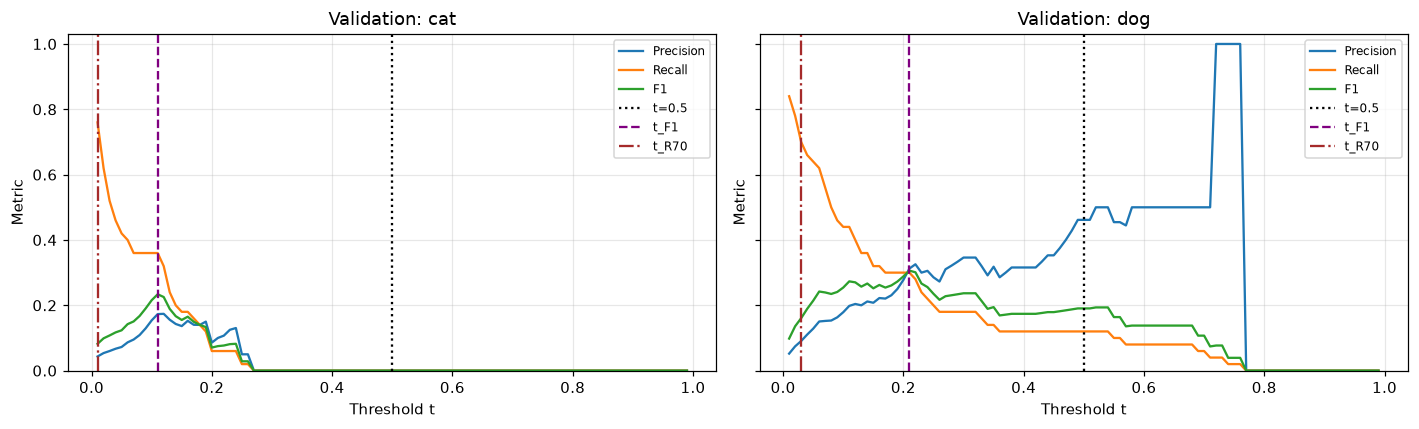

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, c in zip(axes, rare_classes):
    values = thresholds[c]["values"]
    for j, label in enumerate(["Precision", "Recall", "F1"]):
        ax.plot(threshold_grid, values[:, j], label=label)
    ax.axvline(0.5, color="black", linestyle=":", label="t=0.5")
    ax.axvline(thresholds[c]["t_F1"], color="purple", linestyle="--", label="t_F1")
    ax.axvline(thresholds[c]["t_R70"], color="brown", linestyle="-.", label="t_R70")
    ax.set(title=f"Validation: {classes[c]}", xlabel="Threshold t", ylabel="Metric", ylim=(0, 1.03))
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### Your answers: threshold search

- Write `t_F1` and `t_R70` for cat and dog. Are they above or below 0.5? Explain why, using what argmax does with 10 classes.
- From your plot: when `t` goes down, what happens to precision and to recall, and why? Why does F1 have a peak somewhere in the middle?
- By how much does validation recall for cat change when the model finds one more cat? What does this tell you about how exact your chosen thresholds are?

Ответы с результатами текущего запуска — в следующей ячейке.

In [26]:
lines = []
for c in rare_classes:
    a, b = thresholds[c]["t_F1"], thresholds[c]["t_R70"]
    relation_a = "ниже" if a < 0.5 else ("выше" if a > 0.5 else "равен")
    relation_b = "ниже" if b < 0.5 else ("выше" if b > 0.5 else "равен")
    status = "R70 достигнут на validation." if thresholds[c]["reached_R70"] else "R70 недостижим на сетке; выбран максимальный recall."
    lines.append(f"- **{classes[c]}:** t_F1 = **{a:.2f}** ({relation_a} 0.5), t_R70 = **{b:.2f}** ({relation_b} 0.5). {status}")
display(Markdown("\n".join(lines)))
display(Markdown(f"""
Argmax выбирает наибольшую из 10 вероятностей, даже если она меньше 0.5; например, 0.20 может быть максимумом. Поэтому `p(cat) ≥ 0.5` и «cat победил по argmax» — разные правила.

При уменьшении t положительных предсказаний становится больше, и recall не убывает. Precision часто снижается из-за ложных срабатываний, но не обязан меняться монотонно. F1 обычно достигает максимума в компромиссе между пропусками и ложными срабатываниями; внутренний пик не гарантирован.

На validation **{val_counts[3]}** кошек: ещё одна найденная кошка меняет recall на **1/{val_counts[3]} = {1 / val_counts[3]:.2f}**, то есть на **{100 / val_counts[3]:.0f} процентных пункта**. Поэтому пороги оценены довольно грубо; шаг сетки 0.01 не означает такую же точность оптимального порога.
"""))

- **cat:** t_F1 = **0.11** (ниже 0.5), t_R70 = **0.01** (ниже 0.5). R70 достигнут на validation.
- **dog:** t_F1 = **0.21** (ниже 0.5), t_R70 = **0.03** (ниже 0.5). R70 достигнут на validation.


Argmax выбирает наибольшую из 10 вероятностей, даже если она меньше 0.5; например, 0.20 может быть максимумом. Поэтому `p(cat) ≥ 0.5` и «cat победил по argmax» — разные правила.

При уменьшении t положительных предсказаний становится больше, и recall не убывает. Precision часто снижается из-за ложных срабатываний, но не обязан меняться монотонно. F1 обычно достигает максимума в компромиссе между пропусками и ложными срабатываниями; внутренний пик не гарантирован.

На validation **50** кошек: ещё одна найденная кошка меняет recall на **1/50 = 0.02**, то есть на **2 процентных пункта**. Поэтому пороги оценены довольно грубо; шаг сетки 0.01 не означает такую же точность оптимального порога.


### Дополнительный опыт перед финальным test: веса классов

Отдельно обучаем B с весом 10 для cat/dog и 1 для остальных. Это заранее заданный необязательный опыт: он не меняет выбор основной модели A/B. Для него пороги также выбираются исключительно по validation до первого просмотра test.


In [27]:
# Дополнительный опыт: та же B, но с весами классов в loss.
# Все его пороги тоже фиксируем до просмотра test.
set_seed()
train_generator.manual_seed(SEED)
model_weighted = make_cnn(True).to(device)
class_weights = torch.ones(10, device=device)
class_weights[rare_classes] = 10.0
weighted_loss = nn.CrossEntropyLoss(weight=class_weights)
weighted_optimizer = torch.optim.Adam(model_weighted.parameters(), lr=LEARNING_RATE)
for epoch in range(EPOCHS):
    train_one_epoch(model_weighted, train_loader, weighted_loss, weighted_optimizer)
    val_loss, val_acc = evaluate(model_weighted, val_loader, loss_fn)
    print(f"Weighted B epoch {epoch + 1:2}/{EPOCHS}: val loss={val_loss:.4f}, val accuracy={val_acc:.4f}", flush=True)
weighted_val_predictions = get_predictions(model_weighted, val_loader)
weighted_thresholds = {}
for c in rare_classes:
    weighted_thresholds[c] = find_thresholds(weighted_val_predictions[0].numpy() == c,
                                            weighted_val_predictions[2][:, c])
print("Weighted B validation thresholds:")
for c in rare_classes:
    print(classes[c], {key: weighted_thresholds[c][key] for key in ["t_F1", "t_R70"]})

Weighted B epoch  1/15: val loss=1.9190, val accuracy=0.2973


Weighted B epoch  2/15: val loss=1.6890, val accuracy=0.3876


Weighted B epoch  3/15: val loss=1.6603, val accuracy=0.4244


Weighted B epoch  4/15: val loss=1.5318, val accuracy=0.4493


Weighted B epoch  5/15: val loss=1.4673, val accuracy=0.4524


Weighted B epoch  6/15: val loss=1.4203, val accuracy=0.4893


... (6 outputs left out)

Weighted B epoch 13/15: val loss=1.2286, val accuracy=0.5539


Weighted B epoch 14/15: val loss=1.2452, val accuracy=0.5466


Weighted B epoch 15/15: val loss=1.2053, val accuracy=0.5673


Weighted B validation thresholds:
cat {'t_F1': 0.33, 't_R70': 0.09}
dog {'t_F1': 0.54, 't_R70': 0.11}


## 8. Final evaluation on the test set

All decisions are made. Now use the test set, once. Do not change your models, your choice of `best_model` or your thresholds after this point. If you do, say so in your answers.

In [28]:
# Первый и единственный сбор тестовых предсказаний каждого основного кандидата.
# Далее используем эти сохранённые результаты и ничего не перенастраиваем.
test_predictions, test_results = {}, {}
for name, model in models.items():
    test_predictions[name] = get_predictions(model, test_loader)
    test_results[name] = all_metrics(*test_predictions[name])
    print_metrics(f"Test — Model {name}", test_results[name])
    check_with_sklearn(*test_predictions[name], test_results[name])


Test — Model A
Class            N  Precision   Recall       F1       AP
airplane      1000     0.7688   0.5320   0.6288   0.7277
automobile    1000     0.7431   0.5930   0.6596   0.7654
bird          1000     0.4952   0.5120   0.5034   0.5309
cat            100     0.1875   0.0600   0.0909   0.0877
deer          1000     0.5113   0.5660   0.5373   0.5642
dog            100     0.2642   0.1400   0.1830   0.1291
frog          1000     0.6306   0.7750   0.6954   0.7722
horse         1000     0.7457   0.6130   0.6729   0.7670
ship          1000     0.6837   0.7780   0.7278   0.7999
truck         1000     0.5606   0.7260   0.6327   0.6995
Accuracy=0.6238, macro F1=0.5332, weighted F1=0.6202, macro AP=0.5844
bird: AP difference from score ties = 0.00000034
ship: AP difference from score ties = 0.00000033
sklearn: macro AP=0.584358; our macro AP=0.584358
Confusion matrix, precision, recall, F1 and accuracy match sklearn.



Test — Model B
Class            N  Precision   Recall       F1       AP
airplane      1000     0.6966   0.5510   0.6153   0.7032
automobile    1000     0.6340   0.7640   0.6930   0.7754
bird          1000     0.5280   0.3490   0.4202   0.4993
cat            100     0.0000   0.0000   0.0000   0.0946
deer          1000     0.5342   0.4680   0.4989   0.5233
dog            100     0.0000   0.0000   0.0000   0.0945
frog          1000     0.5923   0.7990   0.6803   0.7817
horse         1000     0.6241   0.7190   0.6682   0.7552
ship          1000     0.6903   0.6820   0.6861   0.7642
truck         1000     0.5713   0.6730   0.6180   0.6941
Accuracy=0.6104, macro F1=0.4880, weighted F1=0.5951, macro AP=0.5686
ship: AP difference from score ties = 0.00000114
sklearn: macro AP=0.568551; our macro AP=0.568551
Confusion matrix, precision, recall, F1 and accuracy match sklearn.


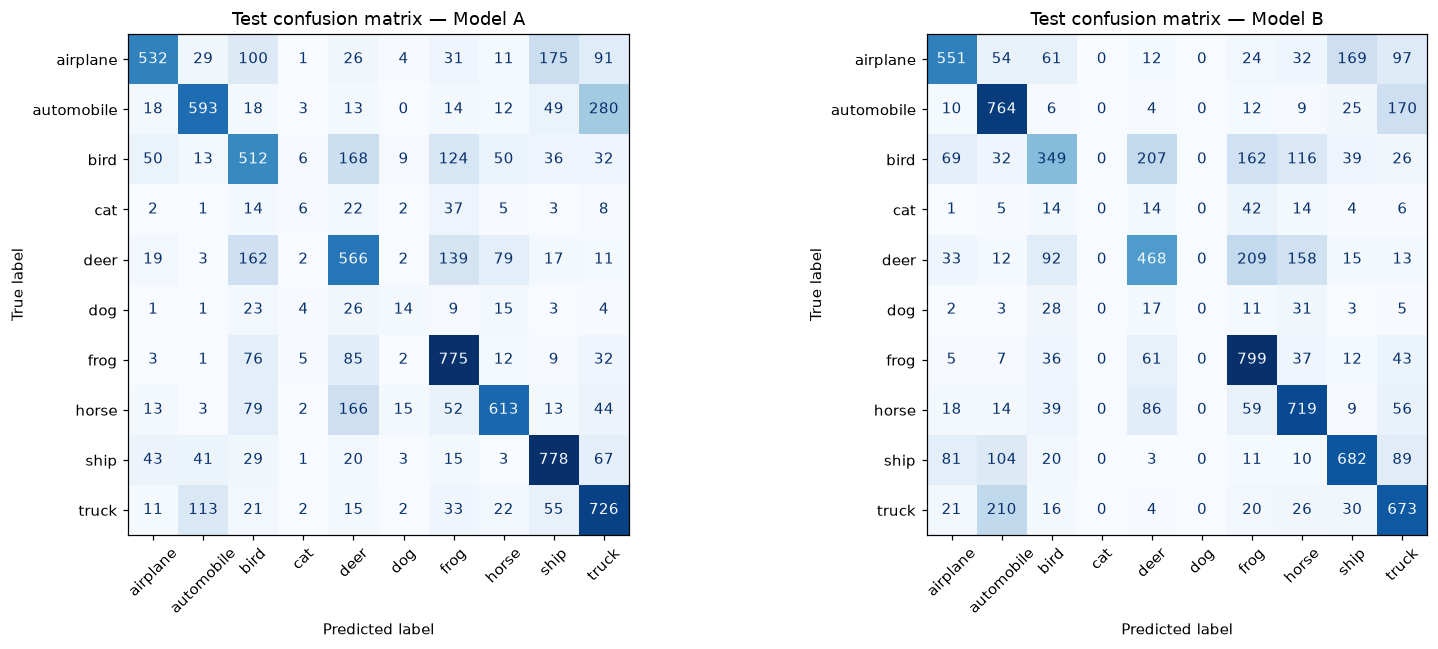

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, name in zip(axes, ["A", "B"]):
    metrics.ConfusionMatrixDisplay(test_results[name]["cm"], display_labels=classes).plot(
        ax=ax, cmap="Blues", colorbar=False, xticks_rotation=45, values_format="d")
    ax.set_title(f"Test confusion matrix — Model {name}")
plt.tight_layout()
plt.show()

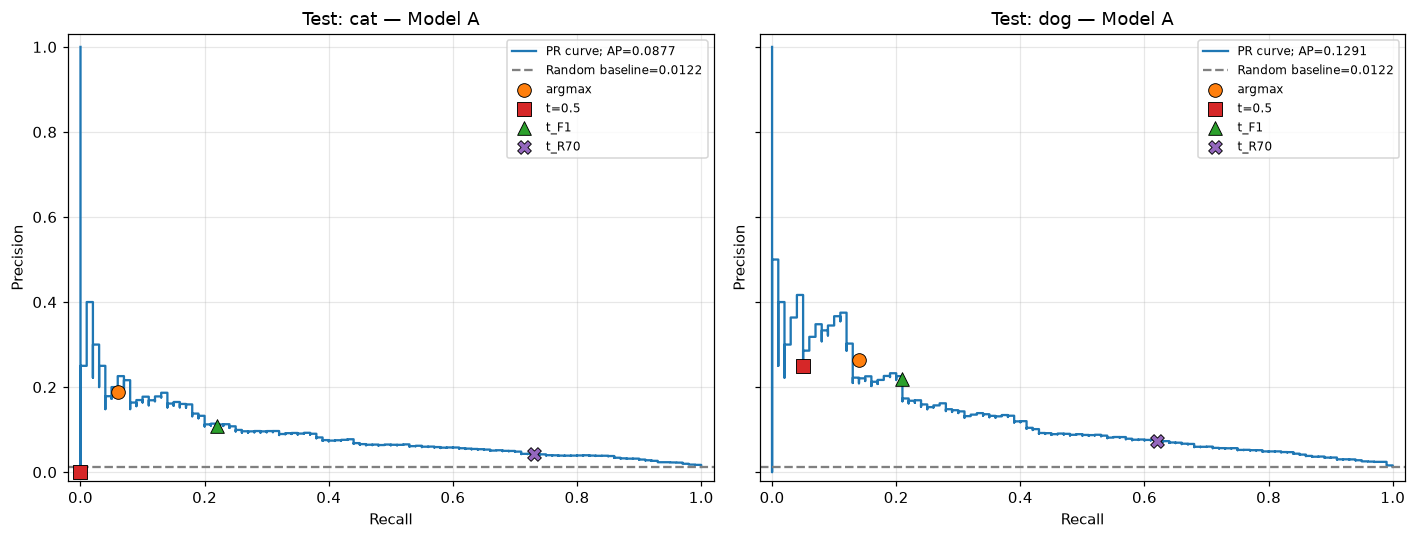

In [30]:
test_true, test_pred, test_prob = test_predictions[best_name]
best_test = test_results[best_name]
operating_points = {}
for c in rare_classes:
    positive = test_true.numpy() == c
    cm = best_test["cm"]
    operating_points[c] = [{"rule": "argmax", "t": None,
                            "count": int(cm[:, c].sum()),
                            "precision": best_test["precision"][c],
                            "recall": best_test["recall"][c], "f1": best_test["f1"][c]}]
    for rule, t in [("t=0.5", 0.5), ("t_F1", thresholds[c]["t_F1"]),
                    ("t_R70", thresholds[c]["t_R70"])]:
        p, r, f1 = prf_at_threshold(positive, test_prob[:, c], t)
        operating_points[c].append({"rule": rule, "t": t,
                                    "count": int((test_prob[:, c] >= t).sum()),
                                    "precision": p, "recall": r, "f1": f1})

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, c in zip(axes, rare_classes):
    p, r, _ = metrics.precision_recall_curve(test_true.numpy() == c, test_prob[:, c])
    ax.step(r, p, where="post", label=f"PR curve; AP={best_test['ap'][c]:.4f}")
    baseline = best_test["support"][c] / len(test_true)
    ax.axhline(baseline, color="gray", linestyle="--", label=f"Random baseline={baseline:.4f}")
    for point, marker, color in zip(operating_points[c], ["o", "s", "^", "X"],
                                     ["tab:orange", "tab:red", "tab:green", "tab:purple"]):
        ax.scatter(point["recall"], point["precision"], marker=marker, s=80,
                   label=point["rule"], color=color, edgecolors="black", linewidths=0.6, zorder=4)
    ax.set(title=f"Test: {classes[c]} — Model {best_name}", xlabel="Recall", ylabel="Precision",
           xlim=(-0.02, 1.02), ylim=(-0.02, 1.03))
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
# Argmax — отдельное правило, поэтому его точка не обязана лежать на PR-кривой одного score.

In [31]:
for c in rare_classes:
    print(f"\nTest — {classes[c]}, model {best_name}")
    print(f"{'Rule':10} {'t':>6} {'Predicted +':>12} {'Precision':>10} {'Recall':>8} {'F1':>8}")
    for point in operating_points[c]:
        t_text = "—" if point["t"] is None else f"{point['t']:.2f}"
        print(f"{point['rule']:10} {t_text:>6} {point['count']:12} {point['precision']:10.4f} "
              f"{point['recall']:8.4f} {point['f1']:8.4f}")


Test — cat, model A
Rule            t  Predicted +  Precision   Recall       F1
argmax          —           32     0.1875   0.0600   0.0909
t=0.5        0.50            3     0.0000   0.0000   0.0000
t_F1         0.11          204     0.1078   0.2200   0.1447
t_R70        0.01         1728     0.0422   0.7300   0.0799

Test — dog, model A
Rule            t  Predicted +  Precision   Recall       F1
argmax          —           53     0.2642   0.1400   0.1830
t=0.5        0.50           20     0.2500   0.0500   0.0833
t_F1         0.21           96     0.2188   0.2100   0.2143
t_R70        0.03          853     0.0727   0.6200   0.1301


#### Your answers: final metrics (explain properly)

1. Fill in for the test set: | Model | accuracy | macro F1 | weighted F1 | macro AP |. Which F1 is closer to accuracy, and why?
2. Explain each metric with your numbers. For the cat class of your best model, write one or two sentences for each of precision, recall, F1 and AP. Use counts from your test confusion matrix, for example: "Of the 80 images we predicted as cat, 30 were real cats, so precision = 30/80 = 0.38." (These numbers are made up, use yours.)
3. What does recall for cat and dog show that accuracy hides? How much accuracy would a model lose if it never predicted cat or dog at all?
4. Compute the random-baseline AP for cat and for airplane on the test set. Is your cat AP good or bad compared with its baseline? Why can the same AP value be good for one class and bad for another?
5. Changing `t` changed F1 for cat, but AP stayed the same. Why? When would you report AP, and when F1 at a chosen threshold?
6. Did Rule R70 still give recall ≥ 0.70 on the test set? Did Rule F1 give the best test F1 of the four rules? Explain any difference using what you know about the size of the validation set.
7. Did Dropout help on the test set? Compare Model A and Model B on macro F1, macro AP, and recall for cat and dog.
8. In the test confusion matrix of your best model, which classes are real cats most often predicted as? Does this make sense?

Ответы с результатами текущего запуска — в следующей ячейке.

In [32]:
display(Markdown("**1. Итоговые метрики**\n\n" + summary_table(test_results)))
for name, r in test_results.items():
    closer = "weighted F1" if abs(r["weighted_f1"] - r["accuracy"]) < abs(r["macro_f1"] - r["accuracy"]) else "macro F1"
    display(Markdown(f"У {name} к accuracy ближе **{closer}**."))

cm = best_test["cm"]
c = 3
tp, predicted_cats, real_cats = int(cm[c, c]), int(cm[:, c].sum()), int(cm[c, :].sum())
fp, fn = predicted_cats - tp, real_cats - tp
cat_ap = best_test["ap"][3]
cat_baseline = test_counts[3] / len(test_set)
plane_baseline = test_counts[0] / len(test_set)
mistakes = cm[3].copy()
mistakes[3] = 0
top_confusions = [i for i in np.argsort(-mistakes) if mistakes[i] > 0][:3]
confusion_text = ", ".join(f"{classes[i]}: {mistakes[i]}" for i in top_confusions) or "ошибок нет"
if top_confusions and top_confusions[0] in [2, 4, 5, 6, 7]:
    confusion_explanation = "Это частые классы животных, а кошек в train в 10 раз меньше. На изображениях 32×32 модель может путать текстуру и фон; точную причину нужно проверять просмотром самих ошибок."
else:
    confusion_explanation = "По одной матрице нельзя установить причину: стоит посмотреть сами ошибки, поскольку модель может опираться на фон и цвет, а не на форму животного."

display(Markdown(f"""
Weighted F1 учитывает частоты классов, поэтому обычно ближе к accuracy; macro F1 даёт редким классам такой же вес, как частым. Совпадение не гарантируется формулами.

**2. Кошки, модель {best_name}, правило argmax.**
- Precision: среди **{predicted_cats}** предсказанных кошек настоящих **{tp}**; precision = **{str(tp) + '/' + str(predicted_cats) if predicted_cats else '0 (нет предсказаний cat)'} = {best_test['precision'][3]:.4f}**. Ложных срабатываний **{fp}**. Если предсказаний нет, precision по принятому соглашению равен 0.
- Recall: из **{real_cats}** настоящих кошек найдено **{tp}**; recall = **{tp}/{real_cats} = {best_test['recall'][3]:.4f}**. Пропущено **{fn}** кошек.
- F1 = **2TP/(2TP+FP+FN) = {2 * tp}/({2 * tp}+{fp}+{fn}) = {best_test['f1'][3]:.4f}**. Это баланс precision и recall: одной высокой величины недостаточно.
- AP = **{cat_ap:.4f}**: средняя precision на позициях настоящих кошек в ранжировании по p(cat). AP оценивает весь порядок изображений, а не один выбранный порог.

**3. Редкие классы и accuracy.** Recall cat = **{best_test['recall'][3]:.4f}**, dog = **{best_test['recall'][5]:.4f}** показывает, какую долю каждого класса нашли. Кошки и собаки занимают всего **{100 * (test_counts[3] + test_counts[5]) / len(test_set):.2f}%** test: даже если не находить ни одну кошку или собаку, теоретически можно получить **{100 * (1 - (test_counts[3] + test_counts[5]) / len(test_set)):.2f}%** accuracy при идеальных ответах на остальных классах. Потеря относительно идеальной модели — {100 * (test_counts[3] + test_counts[5]) / len(test_set):.2f} п.п.; изменение относительно нашей модели зависит и от того, куда уйдут её прежние предсказания.

**4. Случайный AP.** Cat: **100/8200 = {cat_baseline:.4f}**; airplane: **1000/8200 = {plane_baseline:.4f}**. Cat AP нашей модели **{cat_ap:.4f}**, то есть **{cat_ap / cat_baseline:.1f}×** baseline: {'ранжирование лучше случайного' if cat_ap > cat_baseline else 'результат не лучше случайного baseline'}, но это ещё не означает достаточное качество для приложения. Например, AP=0.10 намного выше baseline кошек, но ниже baseline самолётов; AP нужно интерпретировать с учётом распространённости класса. Для конечной случайной выборки baseline — ориентир, а не точное равенство.

**5. AP и F1.** Порог меняет положительные предсказания и F1, но не меняет scores и их ранжирование, поэтому AP остаётся **{cat_ap:.4f}**. AP удобно сообщать для сравнения ранжирования моделей, а F1 — для конкретного рабочего порога вместе с precision и recall.
"""))

display(Markdown("**6. Перенос порогов с validation на test.**"))
for c in rare_classes:
    points = operating_points[c]
    f1_point = points[2]
    r70_point = points[3]
    maximum_f1 = max(p["f1"] for p in points)
    is_best = np.isclose(f1_point["f1"], maximum_f1)
    display(Markdown(f"- **{classes[c]}:** R70 дал recall **{r70_point['recall']:.4f}**, условие 0.70 {'выполнено' if r70_point['recall'] >= 0.70 else 'не выполнено'}. F1 при t_F1 = **{f1_point['f1']:.4f}**, максимум среди четырёх правил = **{maximum_f1:.4f}**: Rule F1 {'делит или достигает максимум' if is_best else 'не оказался лучшим на test'}."))
display(Markdown("На validation только 50 кошек и 50 собак: одна находка меняет recall на 0.02. Пороги подстроены под эту небольшую выборку, поэтому их validation-оптимальность и требование R70 не гарантируются на test; после проверки мы их не меняли."))

display(Markdown("**7. Что изменил Dropout на test.**"))
for key, label in [("macro_f1", "Macro F1"), ("macro_ap", "Macro AP")]:
    a, b = test_results["A"][key], test_results["B"][key]
    display(Markdown(f"- {label}: A **{a:.4f}**, B **{b:.4f}**; B−A = **{b-a:+.4f}**."))
for c in rare_classes:
    a, b = test_results["A"]["recall"][c], test_results["B"]["recall"][c]
    display(Markdown(f"- Recall {classes[c]}: A **{a:.4f}**, B **{b:.4f}**; B−A = **{b-a:+.4f}**."))
helped = test_results["B"]["macro_ap"] > test_results["A"]["macro_ap"]
display(Markdown(f"По macro AP Dropout {'помог' if helped else 'не помог'} в этом запуске; остальные показатели приведены отдельно, так как улучшения не обязаны совпадать. Один seed не доказывает, что результат повторится всегда."))
display(Markdown(f"**8. Ошибки на кошках.** Чаще всего реальные кошки ошибочно отнесены к: **{confusion_text}**. {confusion_explanation}"))

**1. Итоговые метрики**

| Model | accuracy | macro F1 | weighted F1 | macro AP |
|---|---:|---:|---:|---:|
| A | 0.6238 | 0.5332 | 0.6202 | 0.5844 |
| B | 0.6104 | 0.4880 | 0.5951 | 0.5686 |


У A к accuracy ближе **weighted F1**.

У B к accuracy ближе **weighted F1**.


Weighted F1 учитывает частоты классов, поэтому обычно ближе к accuracy; macro F1 даёт редким классам такой же вес, как частым. Совпадение не гарантируется формулами.

**2. Кошки, модель A, правило argmax.**
- Precision: среди **32** предсказанных кошек настоящих **6**; precision = **6/32 = 0.1875**. Ложных срабатываний **26**. Если предсказаний нет, precision по принятому соглашению равен 0.
- Recall: из **100** настоящих кошек найдено **6**; recall = **6/100 = 0.0600**. Пропущено **94** кошек.
- F1 = **2TP/(2TP+FP+FN) = 12/(12+26+94) = 0.0909**. Это баланс precision и recall: одной высокой величины недостаточно.
- AP = **0.0877**: средняя precision на позициях настоящих кошек в ранжировании по p(cat). AP оценивает весь порядок изображений, а не один выбранный порог.

**3. Редкие классы и accuracy.** Recall cat = **0.0600**, dog = **0.1400** показывает, какую долю каждого класса нашли. Кошки и собаки занимают всего **2.44%** test: даже если не находить ни одну кошку или собаку, теоретически можно получить **97.56%** accuracy при идеальных ответах на остальных классах. Потеря относительно идеальной модели — 2.44 п.п.; изменение относительно нашей модели зависит и от того, куда уйдут её прежние предсказания.

**4. Случайный AP.** Cat: **100/8200 = 0.0122**; airplane: **1000/8200 = 0.1220**. Cat AP нашей модели **0.0877**, то есть **7.2×** baseline: ранжирование лучше случайного, но это ещё не означает достаточное качество для приложения. Например, AP=0.10 намного выше baseline кошек, но ниже baseline самолётов; AP нужно интерпретировать с учётом распространённости класса. Для конечной случайной выборки baseline — ориентир, а не точное равенство.

**5. AP и F1.** Порог меняет положительные предсказания и F1, но не меняет scores и их ранжирование, поэтому AP остаётся **0.0877**. AP удобно сообщать для сравнения ранжирования моделей, а F1 — для конкретного рабочего порога вместе с precision и recall.


**6. Перенос порогов с validation на test.**

- **cat:** R70 дал recall **0.7300**, условие 0.70 выполнено. F1 при t_F1 = **0.1447**, максимум среди четырёх правил = **0.1447**: Rule F1 делит или достигает максимум.

... (5 outputs left out)

- Recall cat: A **0.0600**, B **0.0000**; B−A = **-0.0600**.

- Recall dog: A **0.1400**, B **0.0000**; B−A = **-0.1400**.

По macro AP Dropout не помог в этом запуске; остальные показатели приведены отдельно, так как улучшения не обязаны совпадать. Один seed не доказывает, что результат повторится всегда.

**8. Ошибки на кошках.** Чаще всего реальные кошки ошибочно отнесены к: **frog: 37, deer: 22, bird: 14**. Это частые классы животных, а кошек в train в 10 раз меньше. На изображениях 32×32 модель может путать текстуру и фон; точную причину нужно проверять просмотром самих ошибок.

## 9. Участники и использование AI

ФИО указаны по вашему сообщению. **Перед сдачей дополните таблицу фактическим вкладом каждого участника.**

| Student (full name) | Main contribution | How AI was used and checked |
|---|---|---|
| Dastan Karbuzov | [Фактический вклад] | [Что проверил лично] |
| Ibrashov Anuar | [Фактический вклад] | [Что проверил лично] |
| Ibrayev Miras | [Фактический вклад] | [Что проверил лично] |

**Использование AI:** AI подготовил код, пояснения и проверку результатов. В коде есть проверки размеров и состава выборок, отсутствия пересечения train/validation, начальных весов A/B, архитектуры, числа параметров и совпадения метрик со scikit-learn. Это программные проверки; они не заменяют личную проверку и понимание участниками. Добавьте, что каждый участник действительно запускал и проверял самостоятельно.


## 10. Defense checklist and grading

Submit this completed notebook (or an HTML/PDF export with all cells and plots visible) before your defense. Each group has a short (~5 min) defense. Any member may be asked to:

- explain any line of your code: the subsets, every layer of your CNN, and the training steps
- show how the image shape changes through your CNN, and how you got the input size of the first `Linear` layer
- compute the number of parameters of one of your `Conv2d` layers by hand
- explain what Dropout does in train mode and in eval mode, and show the lines in your code where the mode is switched
- explain precision and recall for one class using a row and a column of your confusion matrix
- compute AP by hand for a short ranked list given by the instructor
- explain why the thresholds were chosen on the validation set and not on the test set, and what happens to precision and recall when `t` goes down
- explain why accuracy can look fine while the model fails on cats and dogs
- say what AI helped with and how you checked it

The Week 7 SIS mini-project is worth 4 points:

| Criterion | Full credit requires | Points |
|---|---|---|
| 1. Your CNN and training | Code written by the group runs from top to bottom. The three subsets match the table. The CNN follows every rule in section 2 and is built from PyTorch layers, not a ready-made or pretrained network. Model A and Model B differ only by Dropout. `model.train()` and `model.eval()` are used correctly. Both models are trained with the same settings, and the loss curves of both are plotted with the same y-axis range, a title, axis labels and a legend. | 1 |
| 2. Metrics and threshold search | Confusion matrix, per-class precision, recall, F1 and AP are computed by your own functions and match scikit-learn. The AP function gives 0.833 on the worked example. The best model and all four thresholds are chosen on the validation set only. Plots: confusion matrices with class names, precision/recall/F1 against `t`, and test PR curves with the random baseline and the four operating points. | 1 |
| 3. Explanations | All answer cells are filled in, correct, short, and use your own numbers: Dropout and train vs eval mode, each metric explained for the cat class, AP vs F1 and the random baseline, the threshold trade-off, and how the thresholds worked on the test set. | 1 |
| 4. Oral defense | Each member individually explains the group's code, plots and metrics (checklist above). | 1 |
| Total | | 4 |

How points are given:
- Criteria 1 to 3 are the same for the whole group. Criterion 4 is given to each student separately.
- A criterion that is mostly met, with one listed part missing or wrong, gets 0.5.
- If the test set was used to choose the model or a threshold, criterion 2 gets at most 0.5.
- If the CNN is a ready-made or pretrained network, criterion 1 gets 0.

Optional (no extra points):
- Class weights: pass `weight=` to `nn.CrossEntropyLoss` so rare classes count more (for example 10 for cat and dog, 1 for the rest). Train Model B again. Did recall for cat and dog go up? What happened to accuracy and to the best thresholds?
- ROC-AUC vs AP: for "cat vs not cat" on the test set, compute ROC-AUC with `sklearn.metrics.roc_auc_score` and plot the ROC curve with `sklearn.metrics.RocCurveDisplay`. A random model gets ROC-AUC 0.5 but AP equal to the share of cats. Why does ROC-AUC look much better than AP for a rare class?
- Rare vs hard: cats and dogs are hard classes even in normal, balanced CIFAR-10. How could you check how much of their low recall comes from having few training images, and how much from the classes being hard?
- Thresholds inside the 10-class classifier: predict cat if `p(cat) ≥ t_F1`, otherwise use argmax. What happens to accuracy and to the recall of the other classes?

## Необязательные задания — результаты и объяснения


Optional: weighted B on test
Class            N  Precision   Recall       F1       AP
airplane      1000     0.5791   0.5710   0.5750   0.6533
automobile    1000     0.6695   0.7210   0.6943   0.7476
bird          1000     0.4627   0.3410   0.3926   0.4178
cat            100     0.0866   0.2200   0.1243   0.0870
deer          1000     0.4932   0.4350   0.4623   0.4716
dog            100     0.1042   0.3700   0.1626   0.1292
frog          1000     0.7004   0.5890   0.6399   0.7260
horse         1000     0.6714   0.6150   0.6420   0.7210
ship          1000     0.5869   0.7460   0.6570   0.7149
truck         1000     0.6493   0.5720   0.6082   0.6767
Accuracy=0.5670, macro F1=0.4958, weighted F1=0.5732, macro AP=0.5345
deer: AP difference from score ties = 0.00000134
sklearn: macro AP=0.534507; our macro AP=0.534507
Confusion matrix, precision, recall, F1 and accuracy match sklearn.


Accuracy B: **0.6104**, weighted B: **0.5670**.

- cat: recall B **0.0000**, weighted B **0.2200** (+0.2200). Пороги по validation: t_F1 **0.06→0.33**, t_R70 **0.02→0.09**.

- dog: recall B **0.0000**, weighted B **0.3700** (+0.3700). Пороги по validation: t_F1 **0.06→0.54**, t_R70 **0.02→0.11**.

Вес 10 усиливает штраф за ошибки на редких классах. Это может увеличить их recall, но добавить ложные срабатывания и снизить общую accuracy; фактические изменения показаны выше.

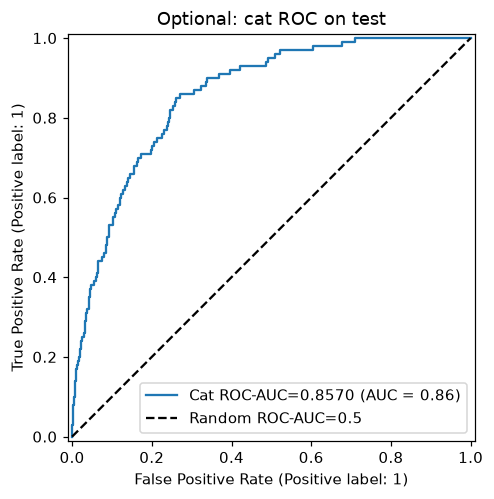

Cat ROC-AUC = **0.8570**, AP = **0.0877**, baseline AP = **0.0122**. ROC использует FPR=FP/(FP+TN): когда отрицательных примеров очень много, заметное число FP может давать маленький FPR. Precision=TP/(TP+FP) прямо показывает загрязнение положительных предсказаний, поэтому AP обычно информативнее для редкого класса; численные значения ROC-AUC и AP напрямую не сравниваются.

**Редкость или сложность?** Обучить ту же CNN ещё на сбалансированном train: по 1000 изображений каждого класса, оставив прежние 100 кошек/собак и добавив 900 непересекающихся с validation. Оставить прежние validation, seed и настройки; сравнить recall/AP кошек и собак на validation и повторить для нескольких seeds. Рост относительно редкого train оценит влияние нехватки данных, а оставшийся разрыв с другими классами — трудность различения; для более строгого контроля выровнять число шагов оптимизатора. В текущем опыте эти два эффекта отдельно не измерены.


Optional: predict cat above t_F1, otherwise argmax
Accuracy: 0.6238 -> 0.6184
Class         Recall argmax  Recall override
airplane             0.5320           0.5320
automobile           0.5930           0.5920
bird                 0.5120           0.5000
cat                  0.0600           0.2200
deer                 0.5660           0.5500
dog                  0.1400           0.0700
frog                 0.7750           0.7640
horse                0.6130           0.6080
ship                 0.7780           0.7740
truck                0.7260           0.7220


Override добавляет предсказания cat: recall кошек не уменьшается, а recall остальных классов не может вырасти, потому что их ответы меняются только в cat. Общая accuracy может как вырасти, так и снизиться; порог и выбранную модель после этого сравнения не меняем.

In [33]:
# 1. Class weights: отдельная модель, основные A/B и best_model не меняем.
weighted_test_predictions = get_predictions(model_weighted, test_loader)
weighted_test = all_metrics(*weighted_test_predictions)
print_metrics("Optional: weighted B on test", weighted_test)
check_with_sklearn(*weighted_test_predictions, weighted_test)
display(Markdown(f"Accuracy B: **{test_results['B']['accuracy']:.4f}**, weighted B: **{weighted_test['accuracy']:.4f}**."))
for c in rare_classes:
    old = test_results["B"]["recall"][c]
    new = weighted_test["recall"][c]
    old_t = find_thresholds(val_predictions["B"][0].numpy() == c, val_predictions["B"][2][:, c])
    new_t = weighted_thresholds[c]
    display(Markdown(f"- {classes[c]}: recall B **{old:.4f}**, weighted B **{new:.4f}** ({new-old:+.4f}). Пороги по validation: t_F1 **{old_t['t_F1']:.2f}→{new_t['t_F1']:.2f}**, t_R70 **{old_t['t_R70']:.2f}→{new_t['t_R70']:.2f}**."))
display(Markdown("Вес 10 усиливает штраф за ошибки на редких классах. Это может увеличить их recall, но добавить ложные срабатывания и снизить общую accuracy; фактические изменения показаны выше."))

# 2. ROC-AUC vs AP: используем уже сохранённые test scores.
cat_true = test_true.numpy() == 3
cat_scores = test_prob[:, 3].numpy()
auc = metrics.roc_auc_score(cat_true, cat_scores)
metrics.RocCurveDisplay.from_predictions(cat_true, cat_scores, name=f"Cat ROC-AUC={auc:.4f}")
plt.plot([0, 1], [0, 1], "k--", label="Random ROC-AUC=0.5")
plt.title("Optional: cat ROC on test")
plt.legend()
plt.show()
display(Markdown(f"Cat ROC-AUC = **{auc:.4f}**, AP = **{cat_ap:.4f}**, baseline AP = **{cat_baseline:.4f}**. ROC использует FPR=FP/(FP+TN): когда отрицательных примеров очень много, заметное число FP может давать маленький FPR. Precision=TP/(TP+FP) прямо показывает загрязнение положительных предсказаний, поэтому AP обычно информативнее для редкого класса; численные значения ROC-AUC и AP напрямую не сравниваются."))

# 3. Rare vs hard: план контролируемого эксперимента, новых test решений нет.
display(Markdown("**Редкость или сложность?** Обучить ту же CNN ещё на сбалансированном train: по 1000 изображений каждого класса, оставив прежние 100 кошек/собак и добавив 900 непересекающихся с validation. Оставить прежние validation, seed и настройки; сравнить recall/AP кошек и собак на validation и повторить для нескольких seeds. Рост относительно редкого train оценит влияние нехватки данных, а оставшийся разрыв с другими классами — трудность различения; для более строгого контроля выровнять число шагов оптимизатора. В текущем опыте эти два эффекта отдельно не измерены."))

# 4. Cat override: правило задано заранее, порог взят из validation.
override_pred = test_pred.numpy().copy()
override_pred[cat_scores >= thresholds[3]["t_F1"]] = 3
override_result = classification_metrics(test_true, override_pred)
print("\nOptional: predict cat above t_F1, otherwise argmax")
print(f"Accuracy: {best_test['accuracy']:.4f} -> {override_result['accuracy']:.4f}")
print(f"{'Class':12} {'Recall argmax':>14} {'Recall override':>16}")
for c in range(10):
    print(f"{classes[c]:12} {best_test['recall'][c]:14.4f} {override_result['recall'][c]:16.4f}")
display(Markdown("Override добавляет предсказания cat: recall кошек не уменьшается, а recall остальных классов не может вырасти, потому что их ответы меняются только в cat. Общая accuracy может как вырасти, так и снизиться; порог и выбранную модель после этого сравнения не меняем."))